# Выбор генеративной модели

В блокноте сравниваются локальные языковые модели для генерации ответа по найденным фрагментам регламента. Главный критерий — понимание перефразированных вопросов: вопрос сформулирован другими словами, чем текст регламента, и модель должна понять, что фрагмент отвечает на него. Второй критерий — модель не должна выдумывать ответ, когда его нет во фрагментах (вопросы-ловушки).

Поиск во всех экспериментах одинаковый — лучший вариант из блокнота `parameter_tuning.ipynb`: гибрид RRF с переранжированием. Меняется только генеративная модель, поэтому разница в ответах объясняется моделью, а не поиском.

**Порядок работы:**

1. каждая модель отвечает на одни и те же 36 вопросов: 16 перефразированных, все 25 вопросов ТЗ (часть из них совпадает) и 3 ловушки; прогон повторяется при 3, 5 и 10 фрагментах в контексте;
2. автоматически считаются доля ответов со ссылками на фрагменты и время ответа;
3. ответы размечаются по метрикам ТЗ: точность ответа 0/1/2 и наличие галлюцинаций; модели сравниваются при 5 фрагментах;
4. сравнивается качество ответов при 3, 5 и 10 фрагментах, как требует ТЗ;
5. ошибочные ответы делятся на типы, для каждого типа приводится пример.

**Подготовка.** Модели запускаются через [Ollama](https://ollama.com). Нужно установить Ollama, затем скачать модели командами `ollama pull <модель>` из списка ниже. Модели 7–8B в квантовании Q4 занимают около 5 ГБ и работают на процессоре при 16 ГБ оперативной памяти, но медленно: около 1–2 минут на вопрос. Поэтому прогон выполнялся в Google Colab на видеокарте T4, где ответ занимает несколько секунд. Ответы сохраняются в `data/generation/answers.csv` по мере получения, поэтому прерванный прогон продолжается с того же места.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.evaluate import contains, load_queries
from src.generate import answer, source_label
from src.hybrid_retrieval import build_hybrid

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a9a"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c9c4",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e1",
    "axes.axisbelow": True, "font.size": 10,
})

OUT_DIR = ROOT / "data" / "generation"
OUT_DIR.mkdir(parents=True, exist_ok=True)
ANSWERS_PATH = OUT_DIR / "answers.csv"

## 1. Модели и вопросы

Сравниваются модели одного класса — 3–8 млрд параметров, которые помещаются в 16 ГБ оперативной памяти:

- **Qwen2.5 7B** — многоязычная модель Alibaba, одна из сильнейших открытых моделей своего размера на русском языке;
- **Gemma 3 4B** — компактная многоязычная модель Google, проверяет, насколько хватает модели вдвое меньше;
- **YandexGPT 5 Lite 8B** — модель Яндекса, обученная в основном на русских текстах.

Список можно изменить: достаточно поправить `MODELS` и скачать модель через `ollama pull`.

In [ ]:
MODELS = {
    "Qwen2.5 7B": "qwen2.5:7b",
    "Gemma 3 4B": "gemma3:4b",
    "YandexGPT 5 Lite 8B": "hf.co/yandex/YandexGPT-5-Lite-8B-instruct-GGUF",
}

try:
    installed = {m["name"] for m in requests.get("http://localhost:11434/api/tags", timeout=10).json()["models"]}
except requests.ConnectionError:
    installed = None
    print("Ollama не запущена: новые ответы не будут получены, анализ строится по answers.csv")
for label, name in MODELS.items():
    if installed is not None:
        ok = any(i == name or i.split(":")[0] == name.split(":")[0] for i in installed)
        print(f"{label:22s} {name:50s} {'скачана' if ok else 'НЕТ: ollama pull ' + name}")

Qwen2.5 7B             qwen2.5:7b                                         скачана
Gemma 3 4B             gemma3:4b                                          скачана
YandexGPT 5 Lite 8B    hf.co/yandex/YandexGPT-5-Lite-8B-instruct-GGUF     скачана


In [ ]:
queries = [q for q in load_queries() if q["category"] in ("paraphrase", "trap") or q.get("tz")]
print(f"вопросов: {len(queries)}")
pd.Series([q["category"] for q in queries]).value_counts().rename("вопросов").to_frame()

вопросов: 36


,вопросов
paraphrase,16
factoid,11
procedure,4
trap,3
abbreviation,1
table,1


In [ ]:
retriever = build_hybrid("rrf", rerank=True)

## 2. Прогон моделей

Каждая модель отвечает на все вопросы при 3, 5 и 10 фрагментах в контексте. Для 10 фрагментов контекстное окно увеличено до 16 тыс. токенов.

Инструкции модели (отвечать только по фрагментам, ставить ссылки, отказываться, если ответа нет) передаются в начале сообщения пользователя, а не системным сообщением: шаблон чата YandexGPT 5 Lite в Ollama отбрасывает роль system, и в первом прогоне модель их не видела.

Для каждого вопроса сохраняются ответ, источники, время генерации и признак, есть ли ответ в переданных фрагментах (`context_has_answer`). Этот признак показывает, чья ошибка: если правильного фрагмента в контексте нет, модель не могла ответить, и это ошибка поиска, а не генерации.

In [ ]:
COLUMNS = ["model", "k", "query_id", "tz", "category", "question", "answer", "sources",
           "context_has_answer", "seconds", "accuracy", "hallucination", "note"]


def load_answers() -> pd.DataFrame:
    """Читает сохранённые ответы; если файла ещё нет, возвращает пустую таблицу."""
    if ANSWERS_PATH.exists():
        return pd.read_csv(ANSWERS_PATH, dtype={"tz": str}, keep_default_na=False)
    return pd.DataFrame(columns=COLUMNS)


def run(model_label: str, k: int = 5, num_ctx: int = 8192) -> None:
    """Получает ответы модели на все вопросы и дописывает их в answers.csv.

    Уже полученные ответы пропускаются; вопрос, на котором модель вернула ошибку, будет повторён при следующем запуске.
    """
    done = load_answers()
    done_ids = set(done.loc[(done["model"] == model_label) & (done["k"].astype(int) == k), "query_id"])
    todo = [q for q in queries if q["query_id"] not in done_ids]
    for i, q in enumerate(todo, start=1):
        try:
            result = answer(q["query"], retriever, MODELS[model_label], k, num_ctx)
        except (RuntimeError, requests.RequestException) as error:
            print(f"{model_label} k={k}: {q['query_id']} пропущен, {error}")
            continue
        texts = [hit.chunk["text"] for hit in result.sources]
        row = {
            "model": model_label, "k": k, "query_id": q["query_id"], "tz": q.get("tz", ""),
            "category": q["category"], "question": q["query"], "answer": result.text,
            "sources": " | ".join(source_label(hit) for hit in result.sources),
            "context_has_answer": int(any(contains(t, e) for t in texts for e in q["evidence"])),
            "seconds": round(result.seconds, 1), "accuracy": "", "hallucination": "", "note": "",
        }
        pd.DataFrame([row], columns=COLUMNS).to_csv(
            ANSWERS_PATH, mode="a", header=not ANSWERS_PATH.exists(), index=False, encoding="utf-8")
        print(f"{model_label} k={k}: {i}/{len(todo)} {q['query_id']} {result.seconds:.0f} с")

In [ ]:
for label in MODELS:
    for k in (3, 5, 10):
        run(label, k=k, num_ctx=16384 if k == 10 else 8192)

## 3. Соответствие формату и время ответа

Без разметки можно посчитать:

- **ответы со ссылками** — доля ответов, где есть ссылка на фрагмент вида [1], как требует промпт;
- **время, с** — медианное время генерации; медиана, а не среднее, потому что первый ответ каждой модели включает её загрузку в память.

Распознавание ловушек и ложные отказы оцениваются в разделе 4 по разметке.

In [ ]:
def load_typed() -> pd.DataFrame:
    """Читает ответы и приводит столбцы к числам; неразмеченные оценки становятся NaN."""
    df = load_answers()
    for column in ["k", "context_has_answer"]:
        df[column] = df[column].astype(int)
    for column in ["seconds", "accuracy", "hallucination"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")
    df["cited"] = df["answer"].str.contains(r"\[\d+\]").astype(int)
    return df


def format_metrics(df: pd.DataFrame) -> pd.Series:
    """Считает долю ответов со ссылками на фрагменты и медианное время ответа."""
    return pd.Series({
        "ответы со ссылками": df.loc[df["category"] != "trap", "cited"].mean(),
        "время, с": df["seconds"].median(),
    })


answers = load_typed()
k5 = answers[answers["k"] == 5]
k5.groupby("model")[["category", "cited", "seconds"]].apply(format_metrics).reindex(list(MODELS)).round(3)

,ответы со ссылками,"время, с"
model,,
Qwen2.5 7B,0.788,1.9
Gemma 3 4B,0.818,2.1
YandexGPT 5 Lite 8B,0.939,1.8


In [ ]:
print("Доля вопросов, у которых ответ есть в 5 переданных фрагментах:")
answerable = k5[k5["category"] != "trap"].drop_duplicates("query_id")
answerable.groupby("category")["context_has_answer"].mean().round(2)

Доля вопросов, у которых ответ есть в 5 переданных фрагментах:


category
abbreviation    1.00
factoid         1.00
paraphrase      0.94
procedure       1.00
table           1.00
Name: context_has_answer, dtype: float64

## 4. Разметка ответов

Метрики ТЗ «точность ответа» и «доля галлюцинаций» требуют оценки каждого ответа. В `data/generation/answers.csv` для каждой строки заполнены три столбца:

- `accuracy`: **2** — ответ верный и полный, **1** — частично верный, **0** — неверный или нет ответа; для ловушки 2 — модель отказалась отвечать, 0 — выдумала ответ;
- `hallucination`: **1** — в ответе есть факт, которого нет в переданных фрагментах, **0** — нет;
- `note` — краткое обоснование оценки.

Ответы сверялись с фразами-доказательствами из `data/queries.jsonl` и с текстом переданных фрагментов (столбец `sources`). Разметка выполнена с помощью LLM и выборочно проверена вручную.

In [ ]:
marked = answers.dropna(subset=["accuracy", "hallucination"]).copy()
print(f"размечено: {len(marked)} из {len(answers)}")
marked["paraphrase"] = marked["category"] == "paraphrase"


def manual_metrics(df: pd.DataFrame) -> pd.Series:
    """Считает точность и долю галлюцинаций одной модели по разметке."""
    para = df[df["paraphrase"]]
    return pd.Series({
        "точность, все (0–2)": df["accuracy"].mean(),
        "верных ответов, все": (df["accuracy"] == 2).mean(),
        "точность, перефразы (0–2)": para["accuracy"].mean(),
        "верных ответов, перефразы": (para["accuracy"] == 2).mean(),
        "галлюцинации": df["hallucination"].mean(),
        "ловушки распознаны": (df.loc[df["category"] == "trap", "accuracy"] == 2).mean(),
    })


manual = marked[marked["k"] == 5].groupby("model")[["category", "paraphrase", "accuracy", "hallucination"]].apply(
    manual_metrics).reindex(list(MODELS)).dropna(how="all")
manual.round(3) if len(manual) else "Ответы ещё не размечены: заполните accuracy и hallucination в answers.csv"

размечено: 324 из 324


,"точность, все (0–2)","верных ответов, все","точность, перефразы (0–2)","верных ответов, перефразы",галлюцинации,ловушки распознаны
model,,,,,,
Qwen2.5 7B,1.361,0.667,1.000,0.500,0.028,1.000
Gemma 3 4B,1.472,0.667,1.312,0.562,0.028,0.667
YandexGPT 5 Lite 8B,1.889,0.944,1.875,0.938,0.000,1.000


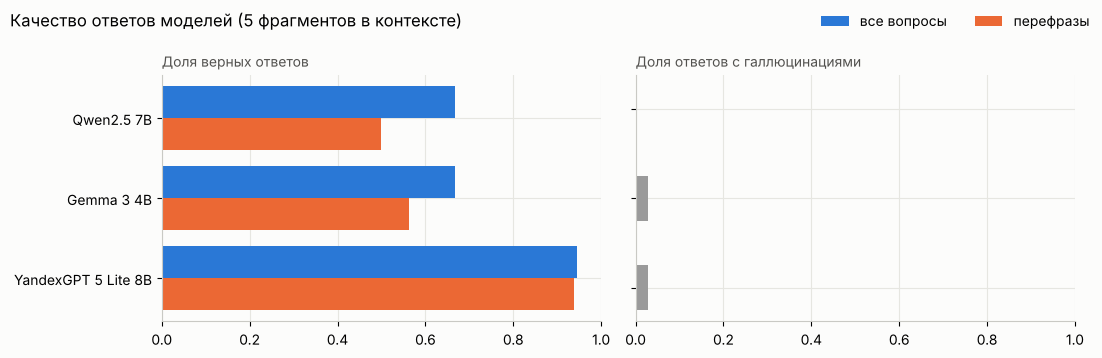

In [ ]:
def plot_manual(manual: pd.DataFrame) -> None:
    """Рисует долю верных ответов и долю галлюцинаций по моделям."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    fig.suptitle("Качество ответов моделей (5 фрагментов в контексте)", x=0.01, ha="left", fontsize=12)
    y = np.arange(len(manual))
    axes[0].barh(y - 0.2, manual["верных ответов, все"], 0.4, color=BLUE, label="все вопросы")
    axes[0].barh(y + 0.2, manual["верных ответов, перефразы"], 0.4, color=ORANGE, label="перефразы")
    axes[0].set_title("Доля верных ответов", loc="left", fontsize=10, color="#52514e")
    axes[1].barh(y, manual["галлюцинации"], 0.5, color=GREY)
    axes[1].set_title("Доля ответов с галлюцинациями", loc="left", fontsize=10, color="#52514e")
    for ax in axes:
        ax.set_yticks(y, manual.index)
        ax.set_xlim(0, 1)
    axes[0].invert_yaxis()
    axes[1].set_yticklabels([])
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
    plt.tight_layout()


if len(manual):
    plot_manual(manual)
else:
    print("Сначала разметьте ответы")

**Вывод.** Лучше всех перефразированные вопросы понимает YandexGPT 5 Lite 8B: 94 % верных ответов на перефразах против 50 % у Qwen2.5 7B и 56 % у Gemma 3 4B, по всем вопросам — 94 % против 67 % у обеих. Она распознала все три ловушки, ни разу не добавила фактов сверх фрагментов и ставит ссылки на фрагменты в 94 % ответов. По времени она не уступает остальным: медиана около 2 с на ответ.

Qwen2.5 7B тоже распознала все ловушки и почти не выдумывает, но часто вместо ответа выдаёт только номер фрагмента «[1]» или отказывается, хотя ответ есть в контексте. Gemma 3 4B на одну ловушку выдумала ответ и часто копирует фрагмент целиком вместе с подписью вместо ответа.

По главному критерию — пониманию перефразов — выбирается YandexGPT 5 Lite 8B.

## 5. Число фрагментов в контексте

ТЗ требует сравнить качество ответов при 3, 5 и 10 фрагментах. Больше фрагментов — выше шанс, что ответ есть в контексте, но модели сложнее найти его среди лишнего текста, и ответ генерируется дольше. Сравнение сделано для всех трёх моделей: так видно, зависит ли влияние объёма контекста от модели.

In [ ]:
answers = load_typed()
marked = answers.dropna(subset=["accuracy", "hallucination"])
by_k = answers[answers["category"] != "trap"].groupby(["model", "k"])[["context_has_answer"]].mean().rename(
    columns={"context_has_answer": "ответ есть в контексте"})
by_k["время, с"] = answers.groupby(["model", "k"])["seconds"].median()
by_k = by_k.join(marked.groupby(["model", "k"]).agg(
    **{"точность (0–2)": ("accuracy", "mean"),
       "верных ответов": ("accuracy", lambda s: (s == 2).mean()),
       "галлюцинации": ("hallucination", "mean")}))
by_k = by_k.join(marked[marked["category"] == "paraphrase"].groupby(["model", "k"])["accuracy"].apply(
    lambda s: (s == 2).mean()).rename("верных на перефразах"))
by_k.round(3)

ответ есть в контексте  время, с  точность (0–2)  \
model               k                                                      
Gemma 3 4B          3                    0.939      1.20           1.583   
                    5                    0.970      2.10           1.472   
                    10                   1.000      3.60           1.750   
Qwen2.5 7B          3                    0.939      1.65           1.444   
                    5                    0.970      1.90           1.361   
                    10                   1.000      4.25           1.194   
YandexGPT 5 Lite 8B 3                    0.939      1.65           1.861   
                    5                    0.970      1.80           1.889   
                    10                   1.000      4.00           1.944   

                        верных ответов  галлюцинации  верных на перефразах  
model               k                                                       
Gemma 3 4B          3            0.750         0.000                 0.750  
                    5            0.667         0.028                 0.562  
                    10           0.861         0.056                 0.938  
Qwen2.5 7B          3            0.667         0.000                 0.562  
                    5            0.667         0.028                 0.500  
                    10           0.556         0.000                 0.500  
YandexGPT 5 Lite 8B 3            0.917         0.000                 0.875  
                    5            0.944         0.000                 0.938  
                    10           0.944         0.056                 0.938

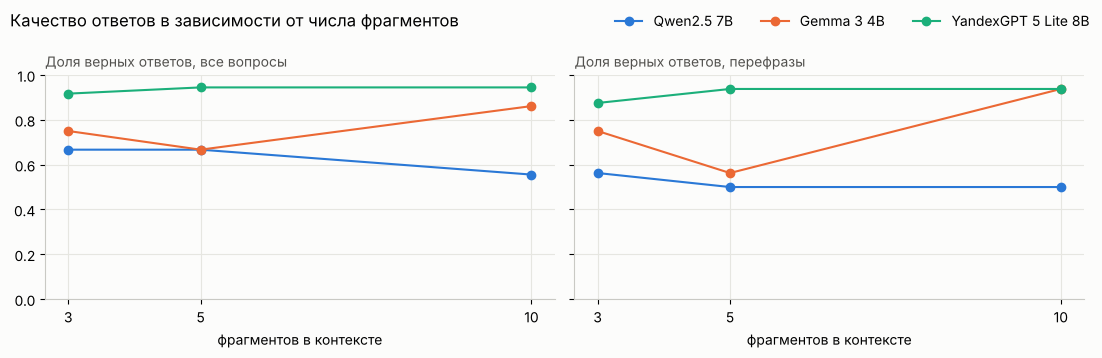

In [ ]:
def plot_by_k(by_k: pd.DataFrame) -> None:
    """Рисует долю верных ответов при 3, 5 и 10 фрагментах для каждой модели."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    fig.suptitle("Качество ответов в зависимости от числа фрагментов", x=0.01, ha="left", fontsize=12)
    for (label, color) in zip(MODELS, [BLUE, ORANGE, AQUA]):
        if label not in by_k.index.get_level_values("model"):
            continue
        part = by_k.loc[label]
        axes[0].plot(part.index, part["верных ответов"], "o-", color=color, label=label)
        axes[1].plot(part.index, part["верных на перефразах"], "o-", color=color)
    axes[0].set_title("Доля верных ответов, все вопросы", loc="left", fontsize=10, color="#52514e")
    axes[1].set_title("Доля верных ответов, перефразы", loc="left", fontsize=10, color="#52514e")
    for ax in axes:
        ax.set_xticks([3, 5, 10])
        ax.set_xlabel("фрагментов в контексте")
        ax.set_ylim(0, 1)
    fig.legend(loc="upper right", ncol=3, frameon=False)
    plt.tight_layout()


if by_k["верных ответов"].notna().any():
    plot_by_k(by_k)
else:
    print("Сначала разметьте ответы")

**Вывод.** Для YandexGPT число фрагментов почти не влияет на качество: 92 %, 94 % и 94 % верных ответов при 3, 5 и 10 фрагментах. При 3 фрагментах ответ есть в контексте для 94 % вопросов, при 5 — для 97 %, при 10 — для всех, но при 10 фрагментах модель дважды приписала фрагменту то, чего в нём нет, а ответ генерируется вдвое дольше (4 с против 1,8 с). У Qwen длинный контекст ухудшает ответы: 67 %, 67 % и 56 % верных, модель чаще отвечает одной ссылкой без текста. Gemma, наоборот, при 10 фрагментах отвечает лучше (86 % верных против 67 % при 5), но при этом выдумала ответы на две ловушки из трёх.

Для YandexGPT выбрано 5 фрагментов: качество не хуже, чем при 10, галлюцинаций нет, а запас по полноте контекста больше, чем при 3.

## 6. Типичные ошибки

Каждый ответ с оценкой ниже 2 или с галлюцинацией отнесён к одному типу ошибки по заметке разметчика (`note`) и признаку `context_has_answer`:

- **ошибка поиска** — нужного фрагмента нет в контексте, и модель не могла ответить;
- **ссылка вместо ответа** — модель выдаёт только номер фрагмента, например «[1]», без текста ответа;
- **ложный отказ** — «Информация не найдена в регламенте», хотя ответ есть во фрагментах;
- **путаница похожих данных** — взята соседняя строка таблицы, например доля риформата д/с вместо доли риформата;
- **искажение фактов** — к верному ответу добавлен факт, которого нет во фрагментах, или свойство приписано не тому веществу;
- **ответ не на вопрос** — скопирован посторонний фрагмент или только расшифровка сокращения;
- **неполный ответ** — названа только часть ответа;
- **ловушка не распознана** — на вопрос без ответа в регламенте модель не отказалась.

Подсчёт сделан по всем прогонам: 3 модели × 3 размера контекста × 36 вопросов.

In [ ]:
def error_type(row: pd.Series) -> str:
    """Относит ошибочный ответ к одному типу по заметке разметчика и признаку наличия ответа в контексте."""
    note = row["note"]
    if row["category"] == "trap":
        return "ловушка не распознана"
    if not row["context_has_answer"]:
        return "ошибка поиска"
    if "только ссылк" in note or "только «" in note or "обрывки подписей" in note:
        return "ссылка вместо ответа"
    if "ложный отказ" in note:
        return "ложный отказ"
    if "д/с" in note:
        return "путаница похожих данных"
    if row["hallucination"] == 1 or "неверный" in note:
        return "искажение фактов"
    if "посторонний" in note or "не отвечает" in note:
        return "ответ не на вопрос"
    return "неполный ответ"


errors = marked[(marked["accuracy"] < 2) | (marked["hallucination"] == 1)].copy()
errors["тип ошибки"] = errors.apply(error_type, axis=1)
print(f"ошибочных ответов: {len(errors)} из {len(marked)}")
error_table = pd.crosstab(errors["тип ошибки"], errors["model"]).reindex(columns=list(MODELS), fill_value=0)
error_table["всего"] = error_table.sum(axis=1)
error_table.sort_values("всего", ascending=False)

ошибочных ответов: 75 из 324


model,Qwen2.5 7B,Gemma 3 4B,YandexGPT 5 Lite 8B,всего
тип ошибки,,,,
ссылка вместо ответа,25,2,0,27
неполный ответ,5,7,1,13
ложный отказ,5,5,0,10
путаница похожих данных,3,3,1,7
ошибка поиска,2,2,2,6
ответ не на вопрос,0,3,2,5
ловушка не распознана,0,4,0,4
искажение фактов,1,1,1,3


In [ ]:
EXAMPLES = [  # по одному показательному ответу на каждый тип ошибки
    ("YandexGPT 5 Lite 8B", 5, "q50"),
    ("Qwen2.5 7B", 5, "q54"),
    ("Qwen2.5 7B", 5, "q08"),
    ("Qwen2.5 7B", 5, "q73"),
    ("Qwen2.5 7B", 5, "q69"),
    ("YandexGPT 5 Lite 8B", 5, "q70"),
    ("Gemma 3 4B", 5, "q58"),
    ("Gemma 3 4B", 10, "q74"),
]
examples = errors.set_index(["model", "k", "query_id"]).loc[EXAMPLES].reset_index()
examples["answer"] = examples["answer"].str.slice(0, 200)
with pd.option_context("display.max_colwidth", None):
    display(examples[["тип ошибки", "model", "k", "query_id", "question", "answer", "note"]].style.hide(axis="index"))

тип ошибки,model,k,query_id,question,answer,note
ошибка поиска,YandexGPT 5 Lite 8B,5,q50,"Что делать, если во время приготовления партии заканчивается один из компонентов?",Информация не найдена в регламенте.,"ответа в контексте нет (ошибка поиска), модель корректно отказалась"
ссылка вместо ответа,Qwen2.5 7B,5,q54,Почему раньше бензин готовили с лишним запасом по октану?,[1],вместо ответа только ссылка [1]
ложный отказ,Qwen2.5 7B,5,q08,Какое октановое число по моторному методу у алкилата?,Информация не найдена в регламенте.,ложный отказ: ответ был в контексте
путаница похожих данных,Qwen2.5 7B,5,q73,"Какие доли риформата, крекинг-бензина и изомеризата в рецептуре АИ-95?","Доля риформата д/с составляет 31,15 % мас., доля бензина каталитического крекинга — 7,74 % мас., доля изомеризата — 14,67 % мас. [2]","доля риформата дана только для риформата д/с (31,15 вместо 31,69)"
искажение фактов,Qwen2.5 7B,5,q69,Как ароматические углеводороды влияют на свойства бензина?,"Ароматические углеводороды повышают октановое число бензина, но ухудшают его экологические свойства: увеличивают образование нагара и выбросы бензола, снижают стабильность бензина при хранении и спосо","основное верно, но свойства олефинов (стабильность, смолообразование) приписаны ароматике"
ответ не на вопрос,YandexGPT 5 Lite 8B,5,q70,Что характеризует давление паров по Рейду?,"Давление насыщенных паров, определяемое по методу Рейда [1].","дана только расшифровка сокращения, на вопрос не отвечает"
неполный ответ,Gemma 3 4B,5,q58,Чем опасен порошок антиокислителя при работе с ним?,"Порошок присадки при попадании на кожу смывают водой с мылом, при попадании в глаза — обильно промывают водой. Россыпи присадки собирают совком из неискрящего материала в закрываемую тару, место россы","только меры первой помощи, взрывоопасность пыли не названа"
ловушка не распознана,Gemma 3 4B,10,q74,Какой катализатор используется на установке риформинга?,"[2], [4] На установке риформинга используются риформаты двух типов: риформат н/с и риформат д/с. Также используются потоки бензина каталитического крекинга, гидроочищенный бензин каталитического креки",ловушка: вместо отказа выдуман ответ (риформаты названы катализатором)


**Вывод.** Самая частая ошибка — ссылка вместо ответа: 27 из 75 ошибочных ответов, из них 25 у Qwen2.5 7B. Модель находит нужный фрагмент, но вместо пересказа выдаёт только его номер. На втором месте неполные ответы (13) и ложные отказы (10). Ложные отказы есть только у Qwen и Gemma, больше половины из них на вопросе q08 про октановое число алкилата по моторному методу: число стоит в таблице компонентов, и модели его не видят.

Путаница похожих данных (7 ответов) связана с самим регламентом: в рецептуре АИ-95 есть и риформат, и риформат д/с с близкими долями (31,69 и 31,15 % мас.), и модели берут не ту строку. Защита от этого — фильтрация по метаданным и чёткие подписи строк таблиц. Нераспознанные ловушки встречаются только у Gemma 3 4B (4 ответа из 9).

Все 6 ошибок поиска приходятся на один перефразированный вопрос q50 («что делать, если во время приготовления партии заканчивается компонент»): нужный фрагмент не попадает в первые 3 и 5 даже после переранжирования и находится только при 10. Все модели при этом правильно отвечают «Информация не найдена в регламенте», так что ошибка поиска не превращается в выдуманный ответ.

У выбранной конфигурации (YandexGPT 5 Lite 8B, 5 фрагментов) две ошибки из 36: ошибка поиска на q50 и ответ не на вопрос на q70 — на вопрос, что характеризует давление паров по Рейду, модель приводит только расшифровку ДНП из глоссария.

## Итог

Для генерации ответа выбрана модель **YandexGPT 5 Lite 8B** с **5 фрагментами** в контексте: 94 % верных ответов и на всех вопросах, и на перефразированных, все ловушки распознаны, галлюцинаций нет, ссылки на фрагменты есть в 94 % ответов.

Важное наблюдение по ходу работы: шаблон чата YandexGPT в Ollama отбрасывает системное сообщение, поэтому инструкции передаются в начале сообщения пользователя. Без этого модель отвечала без ссылок и не выполняла требования к формату ответа.